# 6. Combinación de modelos y umbral de decisión


In [1]:
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

import sys
from pathlib import Path

PROJECT_PATH = Path("..").resolve()
DATA_PATH = PROJECT_PATH / "data"
FIGURES_PATH = PROJECT_PATH / "figures"
sys.path.append(str(PROJECT_PATH))
RANDOM_STATE = 42

warnings.filterwarnings("ignore")
from predictor import TARGET, CATEGORICAL_FEATURES, engineer_features, encode_categories

## 6.1 Datos de train y folds

In [2]:
train_reservations = pd.read_csv(DATA_PATH / "train.csv")
y_train = train_reservations[TARGET]
X_train = engineer_features(train_reservations)
train_categories = {column: sorted(X_train[column].unique()) for column in CATEGORICAL_FEATURES}
X_train_category = encode_categories(X_train, train_categories)
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

with open(DATA_PATH / "lightgbm_hyperparameters.json") as file:
    lightgbm_hyperparameters = json.load(file)

## 6.2 Predicciones out-of-fold de los tres modelos de boosting
XGBoost y CatBoost con una configuración manual equivalente (árboles profundos, `learning_rate` bajo).

In [3]:
base_model_factories = {
    "LightGBM": (lambda: LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, **lightgbm_hyperparameters), X_train_category),
    "XGBoost": (lambda: XGBClassifier(n_estimators=1500, learning_rate=0.03, max_depth=10, subsample=0.8, colsample_bytree=0.6,
                                      enable_categorical=True, tree_method="hist", max_cat_to_onehot=1, random_state=RANDOM_STATE),
                X_train_category),
    "CatBoost": (lambda: CatBoostClassifier(iterations=1500, learning_rate=0.08, depth=8, cat_features=CATEGORICAL_FEATURES,
                                            random_seed=RANDOM_STATE, verbose=0), X_train),
}


def out_of_fold_predict(build_model, features):
    probabilities = np.zeros(len(features))
    for train_index, validation_index in stratified_kfold.split(features, y_train):
        model = build_model().fit(features.iloc[train_index], y_train.iloc[train_index])
        probabilities[validation_index] = model.predict_proba(features.iloc[validation_index])[:, 1]
    return probabilities


out_of_fold_probabilities = pd.DataFrame({
    model_name: out_of_fold_predict(build_model, features)
    for model_name, (build_model, features) in base_model_factories.items()
})
out_of_fold_probabilities.to_csv(DATA_PATH / "out_of_fold_probabilities.csv", index=False)

## 6.3 Promedio y stacking
El meta-modelo (regresión logística) se entrena sobre predicciones out-of-fold y se evalúa con su propia CV.

In [4]:
DECISION_THRESHOLDS = np.round(np.arange(0.20, 0.801, 0.01), 2)


def best_balanced_accuracy(probabilities):
    scores = [balanced_accuracy_score(y_train, probabilities >= threshold) for threshold in DECISION_THRESHOLDS]
    best_index = int(np.argmax(scores))
    return scores[best_index], DECISION_THRESHOLDS[best_index]


candidate_probabilities = {
    **{model_name: out_of_fold_probabilities[model_name] for model_name in base_model_factories},
    "Promedio LightGBM + XGBoost": out_of_fold_probabilities[["LightGBM", "XGBoost"]].mean(axis=1),
    "Promedio de los 3": out_of_fold_probabilities.mean(axis=1),
    "Stacking (regresión logística)": cross_val_predict(LogisticRegression(), out_of_fold_probabilities, y_train,
                                                        cv=stratified_kfold, method="predict_proba")[:, 1],
}
ensemble_comparison = pd.DataFrame([
    {"model": model_name,
     "roc_auc": roc_auc_score(y_train, probabilities),
     "balanced_accuracy_0.5": balanced_accuracy_score(y_train, probabilities >= 0.5),
     "best_balanced_accuracy": best_balanced_accuracy(probabilities)[0],
     "best_threshold": best_balanced_accuracy(probabilities)[1]}
    for model_name, probabilities in candidate_probabilities.items()
]).set_index("model").sort_values("best_balanced_accuracy")
ensemble_comparison.round(4)

,roc_auc,balanced_accuracy_0.5,best_balanced_accuracy,best_threshold
model,,,,
CatBoost,0.9573,0.8816,0.8838,0.40
XGBoost,0.9597,0.8834,0.8854,0.37
Promedio LightGBM + XGBoost,0.9618,0.8870,0.8880,0.41
LightGBM,0.9615,0.8859,0.8885,0.41
Promedio de los 3,0.9615,0.8873,0.8892,0.41
Stacking (regresión logística),0.9615,0.8874,0.8901,0.42


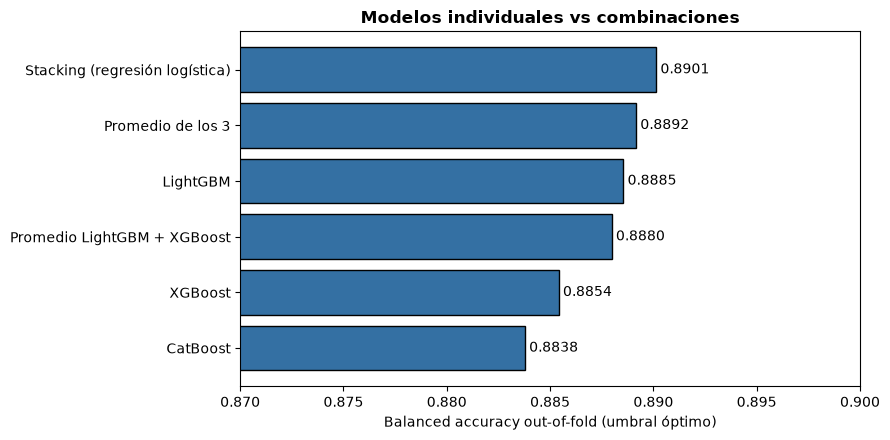

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(ensemble_comparison.index, ensemble_comparison["best_balanced_accuracy"], color="#3470a3", edgecolor="black")
ax.bar_label(bars, fmt="%.4f", padding=3)
ax.set_xlim(0.87, 0.90)
ax.set_xlabel("Balanced accuracy out-of-fold (umbral óptimo)")
ax.set_title("Modelos individuales vs combinaciones", fontweight="bold")
plt.tight_layout()
fig.savefig(FIGURES_PATH / "13_ensemble_comparison.png", dpi=300)
plt.show()

- Promedio y stacking mejoran ≈ 0.001–0.002 de BA respecto de LightGBM solo: dentro de la variación entre folds.
- Se elige **LightGBM solo**: un modelo y una librería en el predictor, con menos riesgo de error de ejecución en la evaluación.

## 6.4 Umbral de decisión para balanced accuracy

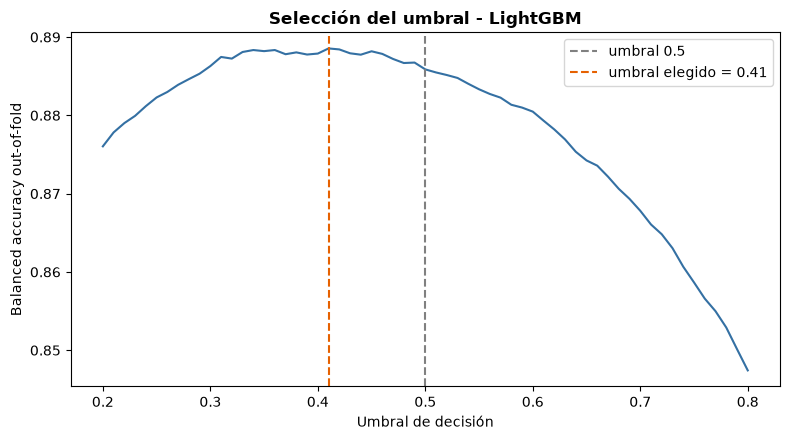

Umbral: 0.41 · BA out-of-fold: 0.8885 (con 0.5: 0.8859)


In [6]:
selected_probabilities = out_of_fold_probabilities["LightGBM"]
threshold_scores = [balanced_accuracy_score(y_train, selected_probabilities >= threshold) for threshold in DECISION_THRESHOLDS]
decision_threshold = float(DECISION_THRESHOLDS[int(np.argmax(threshold_scores))])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(DECISION_THRESHOLDS, threshold_scores, color="#3470a3")
ax.axvline(0.5, color="gray", linestyle="--", label="umbral 0.5")
ax.axvline(decision_threshold, color="#e66101", linestyle="--", label=f"umbral elegido = {decision_threshold:.2f}")
ax.set_xlabel("Umbral de decisión")
ax.set_ylabel("Balanced accuracy out-of-fold")
ax.set_title("Selección del umbral - LightGBM", fontweight="bold")
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES_PATH / "14_decision_threshold.png", dpi=300)
plt.show()

with open(DATA_PATH / "decision_threshold.json", "w") as file:
    json.dump({"decision_threshold": decision_threshold}, file, indent=2)
print(f"Umbral: {decision_threshold:.2f} · BA out-of-fold: {max(threshold_scores):.4f} (con 0.5: {balanced_accuracy_score(y_train, selected_probabilities >= 0.5):.4f})")